# Smoke test: frozen ViT pipeline (run on your laptop)
Same checks as `smoke_test.py`, one step per cell. Uses **ViT-Base (86M)** and a handful of real images, so it runs on CPU or an Apple-silicon Mac.

**Before running:** from the repo root, run `uv sync` and `uv run python common/make_split.py` once. Then choose the `.venv` kernel (VS Code) or the "COMP664 (uv)" kernel (Jupyter).

Each check prints **PASS** or raises an error.

## 0. Setup
Moves to the repo root so the relative paths (`data/...`, `image/pretrained/...`) work from inside `notebooks/`.

In [1]:
import os, sys, subprocess, tempfile
from pathlib import Path

# walk up from this notebook until we find the repo root (the folder containing common/)
root = Path.cwd()
while not (root / "common").is_dir() and root != root.parent:
    root = root.parent
os.chdir(root)
print("repo root:", root)

import torch
import torch.nn as nn
from datasets import load_from_disk
from transformers import AutoImageProcessor, AutoModel

MODEL = "google/vit-base-patch16-224-in21k"
DATA_DIR = "data/informative_agreed_eventsplit"
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

def ok(msg): print("  PASS ", msg)

repo root: /Users/rainacao/Documents/GitHub/comp_664_unc_project


W1117 20:51:43.392000 48457 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps


## 1. Load the shared split and look at a few images

In [2]:
assert os.path.isdir(DATA_DIR), "run `uv run python common/make_split.py` from the repo root first"
dd = load_from_disk(DATA_DIR)
print(dd.num_rows)

imgs   = [dd["train"][i]["image"].convert("RGB") for i in range(8)]
labels = torch.tensor([0 if dd["train"][i]["label"] == "informative" else 1 for i in range(8)])
print("labels (0=informative, 1=not_informative):", labels.tolist())

{'train': 9917, 'dev': 1621, 'test': 1205}
labels (0=informative, 1=not_informative): [0, 0, 0, 0, 0, 1, 1, 1]


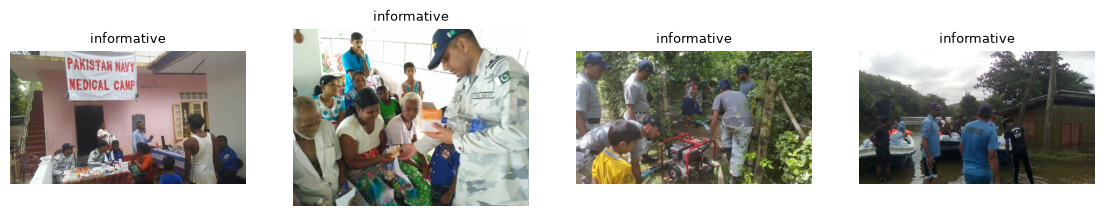

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, im, y in zip(axes, imgs, labels):
    ax.imshow(im); ax.set_title(["informative", "not_informative"][y], fontsize=9); ax.axis("off")
plt.show()

## 2. Load the backbone and freeze it

In [4]:
proc = AutoImageProcessor.from_pretrained(MODEL)
backbone = AutoModel.from_pretrained(MODEL).to(device)
for p in backbone.parameters():
    p.requires_grad = False

n_total = sum(p.numel() for p in backbone.parameters())
n_train = sum(p.numel() for p in backbone.parameters() if p.requires_grad)
assert n_train == 0, f"{n_train} backbone params still trainable"
ok(f"{n_total/1e6:.0f}M backbone params, 0 trainable")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

  PASS  86M backbone params, 0 trainable


## 3. Does freezing hold during training?
Attach a linear head, run a few real optimizer steps through the **full** model (image → ViT → head), then check:
- the backbone has no gradients
- the backbone weights are bit-for-bit unchanged
- the head's weights **did** change (it is learning)

In [5]:
px = proc(images=imgs, return_tensors="pt")["pixel_values"].to(device)
head = nn.Linear(backbone.config.hidden_size, 2).to(device)
opt = torch.optim.AdamW(head.parameters(), lr=1e-2)   # optimizer only sees the head

before_backbone = {k: v.detach().clone() for k, v in backbone.state_dict().items()}
before_head     = {k: v.detach().clone() for k, v in head.state_dict().items()}

backbone.eval()
for step in range(3):
    logits = head(backbone(pixel_values=px).last_hidden_state[:, 0])
    loss = nn.functional.cross_entropy(logits, labels.to(device))
    opt.zero_grad(); loss.backward(); opt.step()
    print(f"step {step} loss {loss.item():.4f}")

step 0 loss 0.7436
step 1 loss 0.3761
step 2 loss 0.1922


In [6]:
assert all(p.grad is None for p in backbone.parameters()), "backbone received gradients"
ok("backbone has no gradients")

changed = [k for k, v in backbone.state_dict().items() if not torch.equal(v, before_backbone[k])]
assert not changed, f"backbone weights changed: {changed[:3]}"
ok("backbone weights identical after training steps")

assert any(not torch.equal(v, before_head[k]) for k, v in head.state_dict().items()), "head did not update"
ok("head weights changed (it is learning)")

  PASS  backbone has no gradients
  PASS  backbone weights identical after training steps
  PASS  head weights changed (it is learning)


## 4. Features are deterministic and the right shape

In [7]:
with torch.no_grad():
    h1 = backbone(pixel_values=px[:2]).last_hidden_state
    h2 = backbone(pixel_values=px[:2]).last_hidden_state

assert torch.allclose(h1, h2), "features differ between runs (dropout on? forgot eval()?)"
ok("same image -> same features (eval mode)")

n_tokens = 1 + (224 // backbone.config.patch_size) ** 2
assert h1.shape == (2, n_tokens, backbone.config.hidden_size), h1.shape
ok(f"shape {tuple(h1.shape)} = (batch, 1 CLS + {n_tokens-1} patches, {backbone.config.hidden_size})")

  PASS  same image -> same features (eval mode)
  PASS  shape (2, 197, 768) = (batch, 1 CLS + 196 patches, 768)


## 5. Run the real scripts on 32 images per split
This runs the exact code the SLURM jobs use, just tiny. Output goes to a temp folder that's deleted afterwards.

In [8]:
tag = MODEL.split("/")[-1]
tmp = tempfile.mkdtemp()
feats, res = f"{tmp}/feats", f"{tmp}/res"

r = subprocess.run([sys.executable, "image/pretrained/scripts/extract_features.py",
                    "--model", MODEL, "--limit", "32", "--batch_size", "16",
                    "--workers", "0", "--out_dir", feats, "--device", device],
                   capture_output=True, text=True)
print(r.stdout[-2000:], r.stderr[-2000:])
assert r.returncode == 0
ok("extract_features.py")

device: mps
splits: {'train': 32, 'dev': 32, 'test': 32}
google/vit-base-patch16-224-in21k: 86M params, 0 trainable
train: 32 images
  batch 0/2
train: features (32, 1536) -> /var/folders/l6/7sq0t_7x02x324f82x6s5d8r0000gn/T/tmpsqqka46q/feats/informative_vit-base-patch16-224-in21k_cls+mean_train.pt
dev: 32 images
  batch 0/2
dev: features (32, 1536) -> /var/folders/l6/7sq0t_7x02x324f82x6s5d8r0000gn/T/tmpsqqka46q/feats/informative_vit-base-patch16-224-in21k_cls+mean_dev.pt
test: 32 images
  batch 0/2
test: features (32, 1536) -> /var/folders/l6/7sq0t_7x02x324f82x6s5d8r0000gn/T/tmpsqqka46q/feats/informative_vit-base-patch16-224-in21k_cls+mean_test.pt
 W1117 20:51:49.142000 48462 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 21753.56it/s]

  PASS  extract_features.py


In [9]:
r = subprocess.run([sys.executable, "image/pretrained/scripts/train_head.py",
                    "--feat_dir", feats, "--results_dir", res,
                    "--prefix", f"informative_{tag}_cls+mean",
                    "--epochs", "5", "--lrs", "1e-3", "--wds", "0", "--verbose"],
                   capture_output=True, text=True)
print(r.stdout[-3000:], r.stderr[-2000:])
assert r.returncode == 0
assert os.path.exists(f"{res}/metrics/informative_{tag}_cls+mean.json")
ok("train_head.py wrote a metrics json")

train (32, 1536)  dev (32, 1536)  test (32, 1536)
train class counts: {'informative': 25, 'not_informative': 7}
majority-class baseline test acc: 0.7812
    epoch   0  train loss 0.7205  dev acc 0.5938  dev macroF1 0.5589
    epoch   4  train loss 0.2789  dev acc 0.6250  dev macroF1 0.6000
lr=0.001   wd=0       best dev: acc=0.6250 macroF1=0.6000 (epoch 1)

chosen: lr=0.001, wd=0, epoch 1, dev macroF1=0.6000

TEST  acc=0.5625  macroF1=0.5556  weightedF1=0.5868
                 precision    recall  f1-score   support

    informative     1.0000    0.4400    0.6111        25
not_informative     0.3333    1.0000    0.5000         7

       accuracy                         0.5625        32
      macro avg     0.6667    0.7200    0.5556        32
   weighted avg     0.8542    0.5625    0.5868        32

confusion matrix [rows=true, cols=pred]:
 [[11 14]
 [ 0  7]]
saved metrics -> /var/folders/l6/7sq0t_7x02x324f82x6s5d8r0000gn/T/tmpsqqka46q/res/metrics/informative_vit-base-patch16-224-in21k_

In [10]:
import shutil; shutil.rmtree(tmp)
print("All checks passed. Safe to push and run the full jobs on Longleaf.")

All checks passed. Safe to push and run the full jobs on Longleaf.
